# Texture Robustness trên Geirhos Cue-Conflict: ResNet-50 và ViT-B/16

## Câu hỏi nghiên cứu

**How robust are ResNet-50 and ViT-B/16 to progressive texture-detail degradation on cue-conflict images?**

Notebook này đo độ ổn định của *mapped 16-category cue decision* trên cùng 1.200 ảnh có shape cue và texture cue xung đột. Đây là **cue-conflict robustness experiment**, không phải benchmark ImageNet Top-1 accuracy. Gaussian Blur làm suy giảm mạnh thành phần tần số cao; Bilateral Filtering làm mịn nội vùng nhưng cố giữ biên. Hai phép biến đổi đều có thể ảnh hưởng shape, vì vậy kết quả được diễn giải như response sensitivity chứ không như phép đo texture bias thuần túy.

**Hypotheses (trước khi xem kết quả):** (i) consistency giảm theo severity; (ii) Gaussian và Bilateral tạo pattern khác nhau; (iii) Shape Bias phải luôn được đọc cùng coverage/Neither, không tự động đồng nghĩa shape recognition tốt hơn.

In [1]:
from pathlib import Path
import sys, json
from collections import Counter

ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, Image as DisplayImage, display

from src.models import load_model
from experiments.shape_texture_bias.controlled_perturbation import cue_decision
from experiments.shape_texture_bias.official_mapping import decisions_from_probabilities
from experiments.texture.cue_conflict_robustness import (
    CONDITIONS, MODELS, apply_transform, id_hash, load_valid_records,
)
from experiments.texture.run_cue_conflict_robustness import (
    OUT, PREDICTIONS_PATH, SUMMARY_PATH, METADATA_PATH, run_experiment, make_figures,
)

plt.style.use('seaborn-v0_8-whitegrid')
FIGURES = OUT / 'figures'
print('Repository:', ROOT)
print('Device:', 'CUDA — ' + torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
print('Prediction cache:', PREDICTIONS_PATH)

Repository: /home/honganh/Documents/tempt/cnn-vit-interpretability
Device: CUDA — NVIDIA GeForce RTX 3060
Prediction cache: /home/honganh/Documents/tempt/cnn-vit-interpretability/results/tv4/texture_predictions.csv


/home/honganh/Documents/tempt/cnn-vit-interpretability/.deps/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Dataset, cohort và model setup

Nguồn ảnh là `rgeirhos/texture-shape-cue-conflict` (test split): 1.280 ảnh stylized, trong đó 80 ảnh có hai cue giống nhau được loại. Cohort hợp lệ gồm đúng 1.200 ID, trùng với Shape-vs-Texture Bias và Controlled Cue Perturbation của TV4. Mapping ImageNet-1K → 16 categories là official mapping đã dùng trong notebook Shape.

In [2]:
records = load_valid_records()
controlled = pd.read_csv(OUT / 'controlled_perturbation_predictions.csv')
controlled_ids = set(controlled.image_id)
record_ids = {r['file_id'] for r in records}
assert len(records) == 1200 and len(record_ids) == 1200
assert record_ids == controlled_ids, 'Texture cohort must equal the Shape controlled cohort'
all_categories = sorted({r['shape_cue'] for r in records} | {r['texture_cue'] for r in records})
print(f'Nguồn: 1.280 images; valid cue-conflict: {len(records):,}; categories: {len(all_categories)}')
print('Cohort ID SHA-256:', id_hash(records))
display(pd.DataFrame([
    {'image_id': r['file_id'], 'shape cue': r['shape_cue'], 'texture cue': r['texture_cue'], 'size': f"{r['image'].size[0]}×{r['image'].size[1]}"}
    for r in records[:8]
]))

Nguồn: 1.280 images; valid cue-conflict: 1,200; categories: 16
Cohort ID SHA-256: 30fb442a86ebf53e6ad3b22f7dbe57867f7a1c009ee58e475fef2c51a185ec21


,image_id,shape cue,texture cue,size
0,cat4-truck3,cat,truck,224×224
1,cat4-oven1,cat,oven,224×224
2,cat2-car3,cat,car,224×224
3,cat9-truck1,cat,truck,224×224
4,cat8-car2,cat,car,224×224
5,cat7-knife2,cat,knife,224×224
6,cat5-bottle1,cat,bottle,224×224
7,cat10-elephant3,cat,elephant,224×224


In [3]:
# Load the fixed project checkpoints and their model-specific official transforms.
resnet, resnet_transform, resnet_meta = load_model('resnet50')
vit, vit_transform, vit_meta = load_model('vit_b_16')
setup = pd.DataFrame([
    {'Model': 'ResNet-50', 'Checkpoint': resnet_meta['weights'], 'Resize / crop': f"{resnet_meta['preprocessing']['resize_size']} / {resnet_meta['preprocessing']['crop_size']}", 'Device': resnet_meta['device']},
    {'Model': 'ViT-B/16', 'Checkpoint': vit_meta['weights'], 'Resize / crop': f"{vit_meta['preprocessing']['resize_size']} / {vit_meta['preprocessing']['crop_size']}", 'Device': vit_meta['device']},
])
display(setup)
parameter_rows = []
for condition, params in CONDITIONS.items():
    parameter_rows.append({'condition': condition, **params})
display(pd.DataFrame(parameter_rows).fillna(''))
print('Gaussian S1/S2 are exactly the completed Shape controlled-perturbation parameters; those validated paired predictions are reused. Gaussian S3 and all Bilateral conditions are additional Texture-Robustness inference.')

,Model,Checkpoint,Resize / crop,Device
0,ResNet-50,ResNet50_Weights.IMAGENET1K_V2,[232] / [224],cuda
1,ViT-B/16,ViT_B_16_Weights.IMAGENET1K_V1,[256] / [224],cuda


/tmp/ipykernel_351635/3447319544.py:12: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(pd.DataFrame(parameter_rows).fillna(''))


,condition,family,severity,kernel_size,sigma,diameter,sigma_color,sigma_space
0,clean,clean,0,,,,,
1,gaussian_s1,gaussian_blur,1,7.0,1.5,,,
2,gaussian_s2,gaussian_blur,2,13.0,3.0,,,
3,gaussian_s3,gaussian_blur,3,19.0,4.5,,,
4,bilateral_s1,bilateral_filter,1,,,5.0,25.0,25.0
5,bilateral_s2,bilateral_filter,2,,,9.0,50.0,50.0
6,bilateral_s3,bilateral_filter,3,,,13.0,100.0,100.0


Gaussian S1/S2 are exactly the completed Shape controlled-perturbation parameters; those validated paired predictions are reused. Gaussian S3 and all Bilateral conditions are additional Texture-Robustness inference.


## 2. Visualizing texture-detail degradation

Mỗi hàng dưới đây là cùng một ảnh: original, Gaussian S1–S3, rồi Bilateral S1–S3. Các phép biến đổi chạy trên RGB gốc trước preprocessing; kích thước và cue labels không đổi. Gaussian ở S3 làm mềm biên/chi tiết mạnh hơn, còn Bilateral có xu hướng bảo toàn biên tương phản trong khi làm mịn bề mặt.

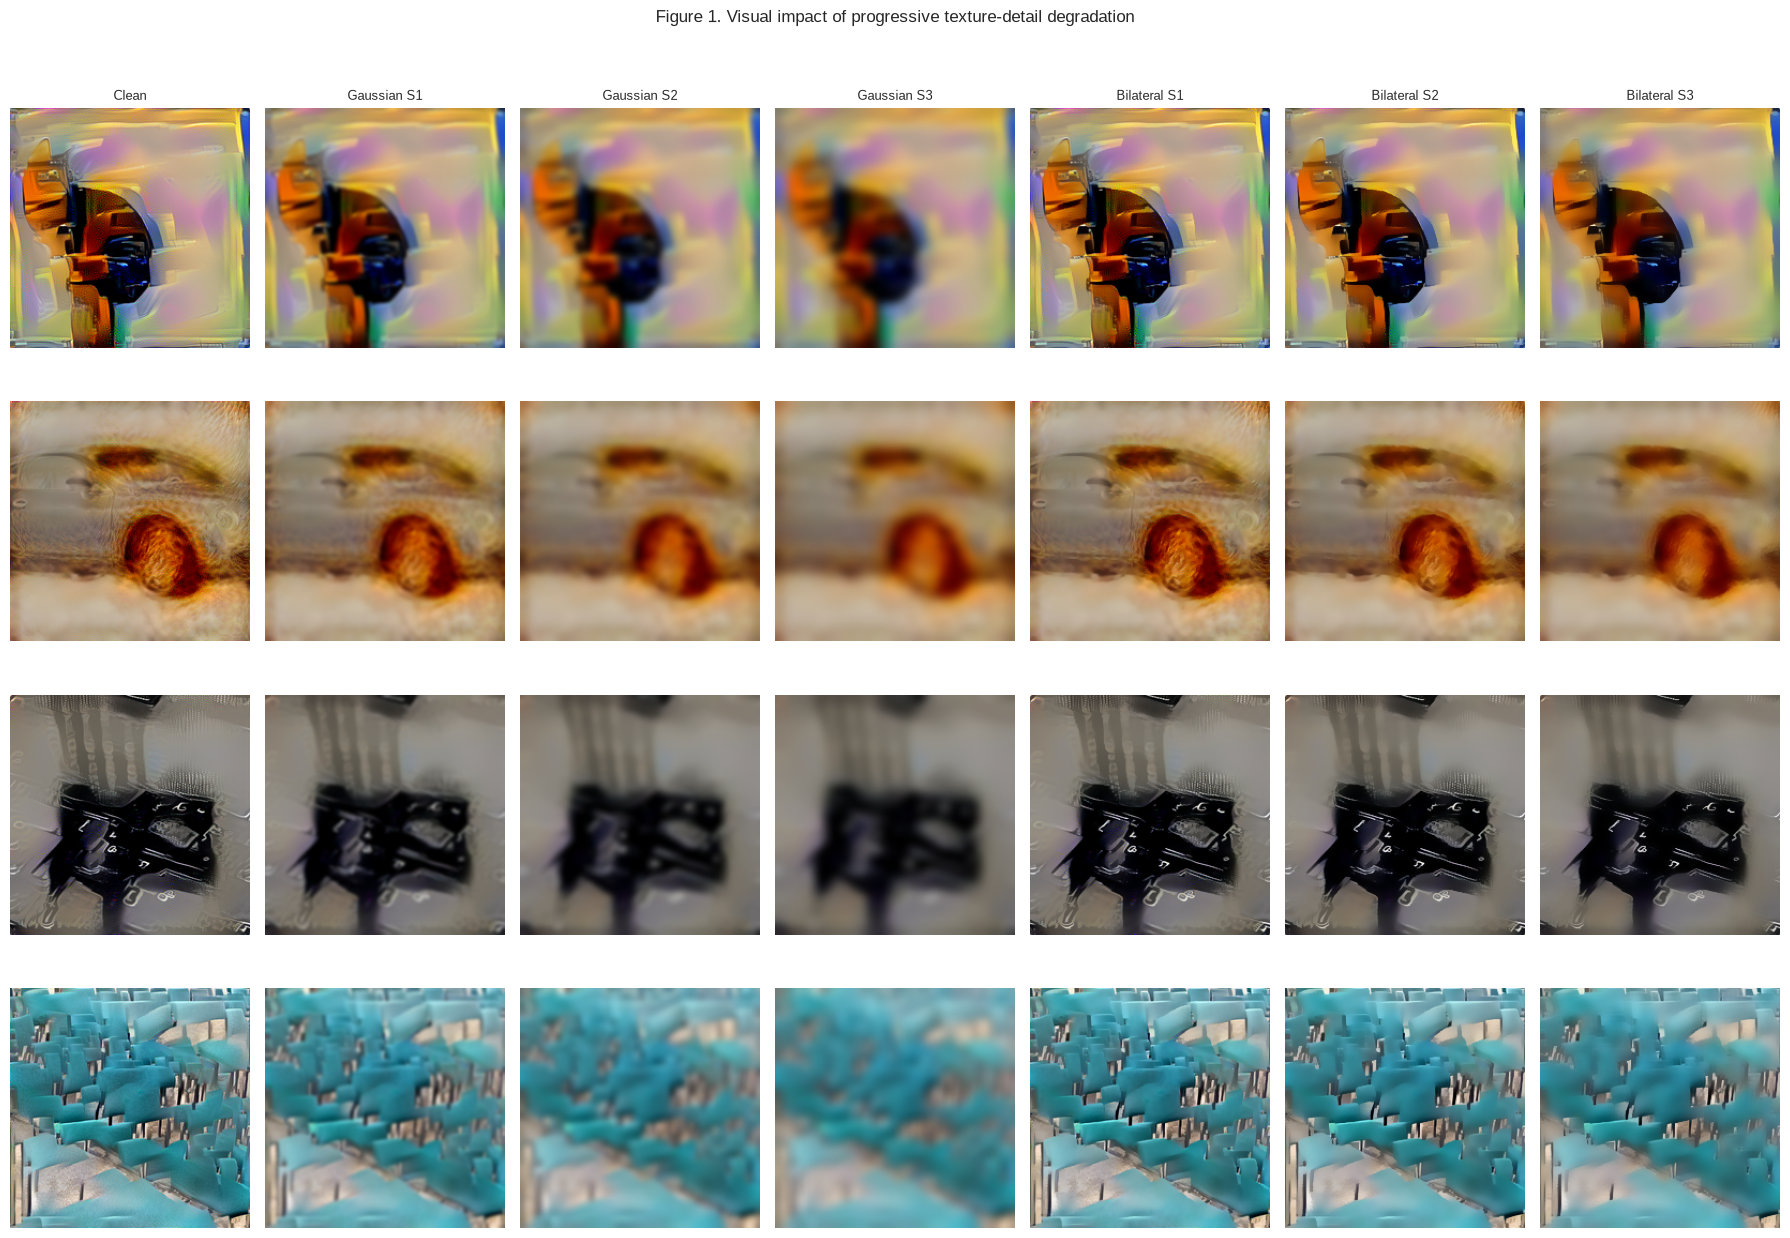

In [4]:
example_indices = [0, 117, 503, 921]
example_records = [records[i] for i in example_indices]
columns = ['clean', 'gaussian_s1', 'gaussian_s2', 'gaussian_s3', 'bilateral_s1', 'bilateral_s2', 'bilateral_s3']
fig, axes = plt.subplots(len(example_records), len(columns), figsize=(18, 3.15 * len(example_records)))
for i, record in enumerate(example_records):
    for j, condition in enumerate(columns):
        ax = axes[i, j]
        ax.imshow(apply_transform(record['image'], condition))
        ax.axis('off')
        if i == 0:
            ax.set_title(condition.replace('_', ' ').title(), fontsize=9)
        if j == 0:
            ax.set_ylabel(f"{record['file_id']}\nshape={record['shape_cue']}\ntexture={record['texture_cue']}", fontsize=8)
fig.suptitle('Figure 1. Visual impact of progressive texture-detail degradation', y=1.01)
fig.tight_layout()
fig.savefig(FIGURES / 'texture_transformation_grid.png', dpi=300, bbox_inches='tight')
plt.show()

## 3. Single-image prediction demo

Model output được softmax trên 1.000 ImageNet classes, sau đó gộp theo official mapping sang 16 cue categories. Decision là **Shape**, **Texture** hoặc **Neither** tùy mapped category có trùng shape cue/texture cue hay không. Các ô bên dưới là inference trực tiếp, không lấy số dựng sẵn.

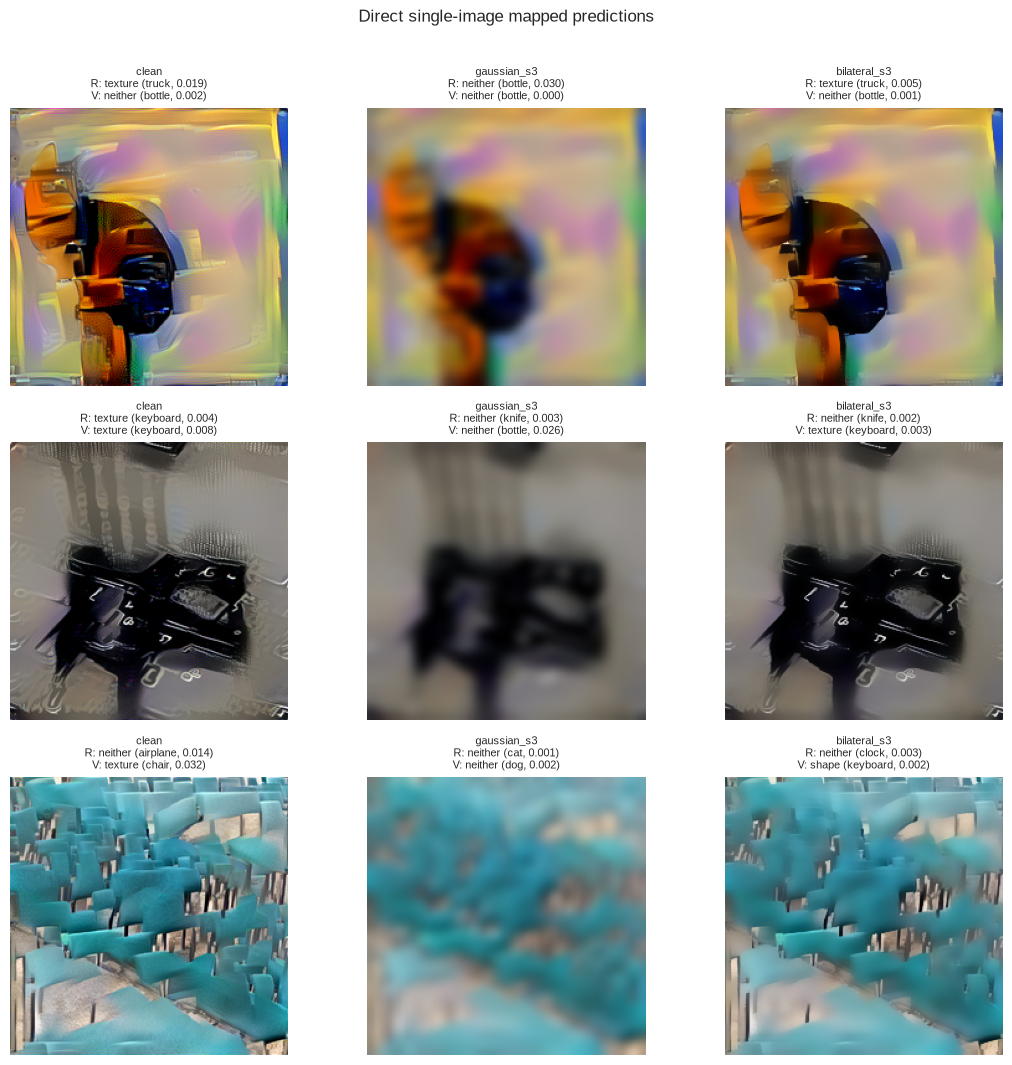

,image_id,condition,model,mapped category,score,decision
0,cat4-truck3,clean,ResNet-50,truck,0.019,texture
1,cat4-truck3,clean,ViT-B/16,bottle,0.002,neither
2,cat4-truck3,gaussian_s3,ResNet-50,bottle,0.030,neither
3,cat4-truck3,gaussian_s3,ViT-B/16,bottle,0.000,neither
4,cat4-truck3,bilateral_s3,ResNet-50,truck,0.005,texture
5,cat4-truck3,bilateral_s3,ViT-B/16,bottle,0.001,neither
6,chair4-keyboard2,clean,ResNet-50,keyboard,0.004,texture
7,chair4-keyboard2,clean,ViT-B/16,keyboard,0.008,texture
8,chair4-keyboard2,gaussian_s3,ResNet-50,knife,0.003,neither
9,chair4-keyboard2,gaussian_s3,ViT-B/16,bottle,0.026,neither


In [5]:
def predict_one(model, transform, record, condition):
    image = apply_transform(record['image'], condition)
    device = next(model.parameters()).device
    with torch.inference_mode(), torch.autocast(device_type=device.type, enabled=device.type == 'cuda'):
        prob = torch.softmax(model(transform(image).unsqueeze(0).to(device)).float(), dim=1).cpu().numpy()
    category, score = decisions_from_probabilities(prob)
    category, score = category[0], float(score[0])
    return category, score, cue_decision(category, record), image

single_records = [records[i] for i in [0, 503, 921]]
single_conditions = ['clean', 'gaussian_s3', 'bilateral_s3']
rows = []
fig, axes = plt.subplots(len(single_records), len(single_conditions), figsize=(11, 3.5 * len(single_records)))
for i, record in enumerate(single_records):
    for j, condition in enumerate(single_conditions):
        r_cat, r_score, r_decision, image = predict_one(resnet, resnet_transform, record, condition)
        v_cat, v_score, v_decision, _ = predict_one(vit, vit_transform, record, condition)
        axes[i, j].imshow(image); axes[i, j].axis('off')
        axes[i, j].set_title(f'{condition}\nR: {r_decision} ({r_cat}, {r_score:.3f})\nV: {v_decision} ({v_cat}, {v_score:.3f})', fontsize=8)
        if j == 0: axes[i, j].set_ylabel(f"{record['file_id']}\nshape={record['shape_cue']}\ntexture={record['texture_cue']}", fontsize=8)
        rows.extend([
            {'image_id': record['file_id'], 'condition': condition, 'model': 'ResNet-50', 'mapped category': r_cat, 'score': r_score, 'decision': r_decision},
            {'image_id': record['file_id'], 'condition': condition, 'model': 'ViT-B/16', 'mapped category': v_cat, 'score': v_score, 'decision': v_decision},
        ])
fig.suptitle('Direct single-image mapped predictions', y=1.01); fig.tight_layout(); plt.show()
display(pd.DataFrame(rows).style.format({'score': '{:.3f}'}))

## 4. Full experiment and verified cache

Có 2 models × 1.200 valid images × 7 conditions = **16.800** prediction records. Cache chỉ được dùng khi khớp đủ image IDs/cue labels, condition parameters, mapping-source hash và protocol metadata. Nếu cache không hợp lệ, cell này tự chạy batched CUDA inference; partial cache được lưu sau từng condition.

In [6]:
# Cached mode by default. Set FORCE_RECOMPUTE=True to rerun every condition.
FORCE_RECOMPUTE = False
# Models shown above are no longer needed before the cache-aware full run.
del resnet, vit
if torch.cuda.is_available(): torch.cuda.empty_cache()
records, prediction_rows, summary_rows, metadata = run_experiment(batch_size=64, force_recompute=FORCE_RECOMPUTE)
# Read canonical CSVs so numeric metric columns retain their numeric dtype in cached mode.
texture_predictions = pd.read_csv(PREDICTIONS_PATH)
texture_summary = pd.read_csv(SUMMARY_PATH)
assert len(texture_predictions) == 2 * 1200 * 7
assert texture_predictions.groupby(['model', 'condition']).size().eq(1200).all()
assert set(texture_predictions.image_id) == {r['file_id'] for r in records}
print('Full experiment records:', len(texture_predictions))
print('Cache metadata:', METADATA_PATH)
display(texture_summary.sort_values(['model','severity','condition']).style.format({
    c: '{:.2f}' for c in texture_summary.columns if c.endswith('_percent')
}))

Full experiment records: 16800
Cache metadata: /home/honganh/Documents/tempt/cnn-vit-interpretability/results/tv4/texture_metadata.json


,model,condition,family,severity,num_images,prediction_consistency_percent,shape_decisions,texture_decisions,neither_decisions,shape_decision_rate_percent,texture_decision_rate_percent,neither_rate_percent,cue_decision_coverage_percent,shape_bias_percent,shape_retention_percent,texture_retention_percent,clean_shape_base,clean_texture_base,kernel_size,sigma,diameter,sigma_color,sigma_space
0,resnet50,clean,clean,0,1200,100.00,181,671,348,15.08,55.92,29.00,71.00,21.24,100.00,100.00,181,671,nan,nan,nan,nan,nan
4,resnet50,bilateral_s1,bilateral_filter,1,1200,79.33,182,613,405,15.17,51.08,33.75,66.25,22.89,85.64,83.76,181,671,nan,nan,5.000000,25.000000,25.000000
1,resnet50,gaussian_s1,gaussian_blur,1,1200,46.58,321,336,543,26.75,28.00,45.25,54.75,48.86,83.43,42.77,181,671,7.000000,1.500000,nan,nan,nan
5,resnet50,bilateral_s2,bilateral_filter,2,1200,64.50,204,538,458,17.00,44.83,38.17,61.83,27.49,81.22,68.41,181,671,nan,nan,9.000000,50.000000,50.000000
2,resnet50,gaussian_s2,gaussian_blur,2,1200,25.83,366,142,692,30.50,11.83,57.67,42.33,72.05,69.06,17.29,181,671,13.000000,3.000000,nan,nan,nan
6,resnet50,bilateral_s3,bilateral_filter,3,1200,50.00,231,422,547,19.25,35.17,45.58,54.42,35.38,73.48,50.97,181,671,nan,nan,13.000000,100.000000,100.000000
3,resnet50,gaussian_s3,gaussian_blur,3,1200,19.00,288,113,799,24.00,9.42,66.58,33.42,71.82,47.51,11.92,181,671,19.000000,4.500000,nan,nan,nan
7,vit_b_16,clean,clean,0,1200,100.00,326,493,381,27.17,41.08,31.75,68.25,39.80,100.00,100.00,326,493,nan,nan,nan,nan,nan
11,vit_b_16,bilateral_s1,bilateral_filter,1,1200,86.83,340,474,386,28.33,39.50,32.17,67.83,41.77,93.87,89.66,326,493,nan,nan,5.000000,25.000000,25.000000
8,vit_b_16,gaussian_s1,gaussian_blur,1,1200,51.50,466,232,502,38.83,19.33,41.83,58.17,66.76,85.28,40.37,326,493,7.000000,1.500000,nan,nan,nan


## 5. Main quantitative results

**Prediction consistency** là tỷ lệ mapped 16-category prediction không đổi so với clean. Shape Bias có mẫu số chỉ gồm Shape+Texture; vì vậy Figure 5 đặt nó cạnh coverage. Retention có mẫu số là chính nhóm clean Shape hoặc clean Texture tương ứng, không phải toàn bộ 1.200 ảnh.

**Figure 2 — Prediction consistency.**

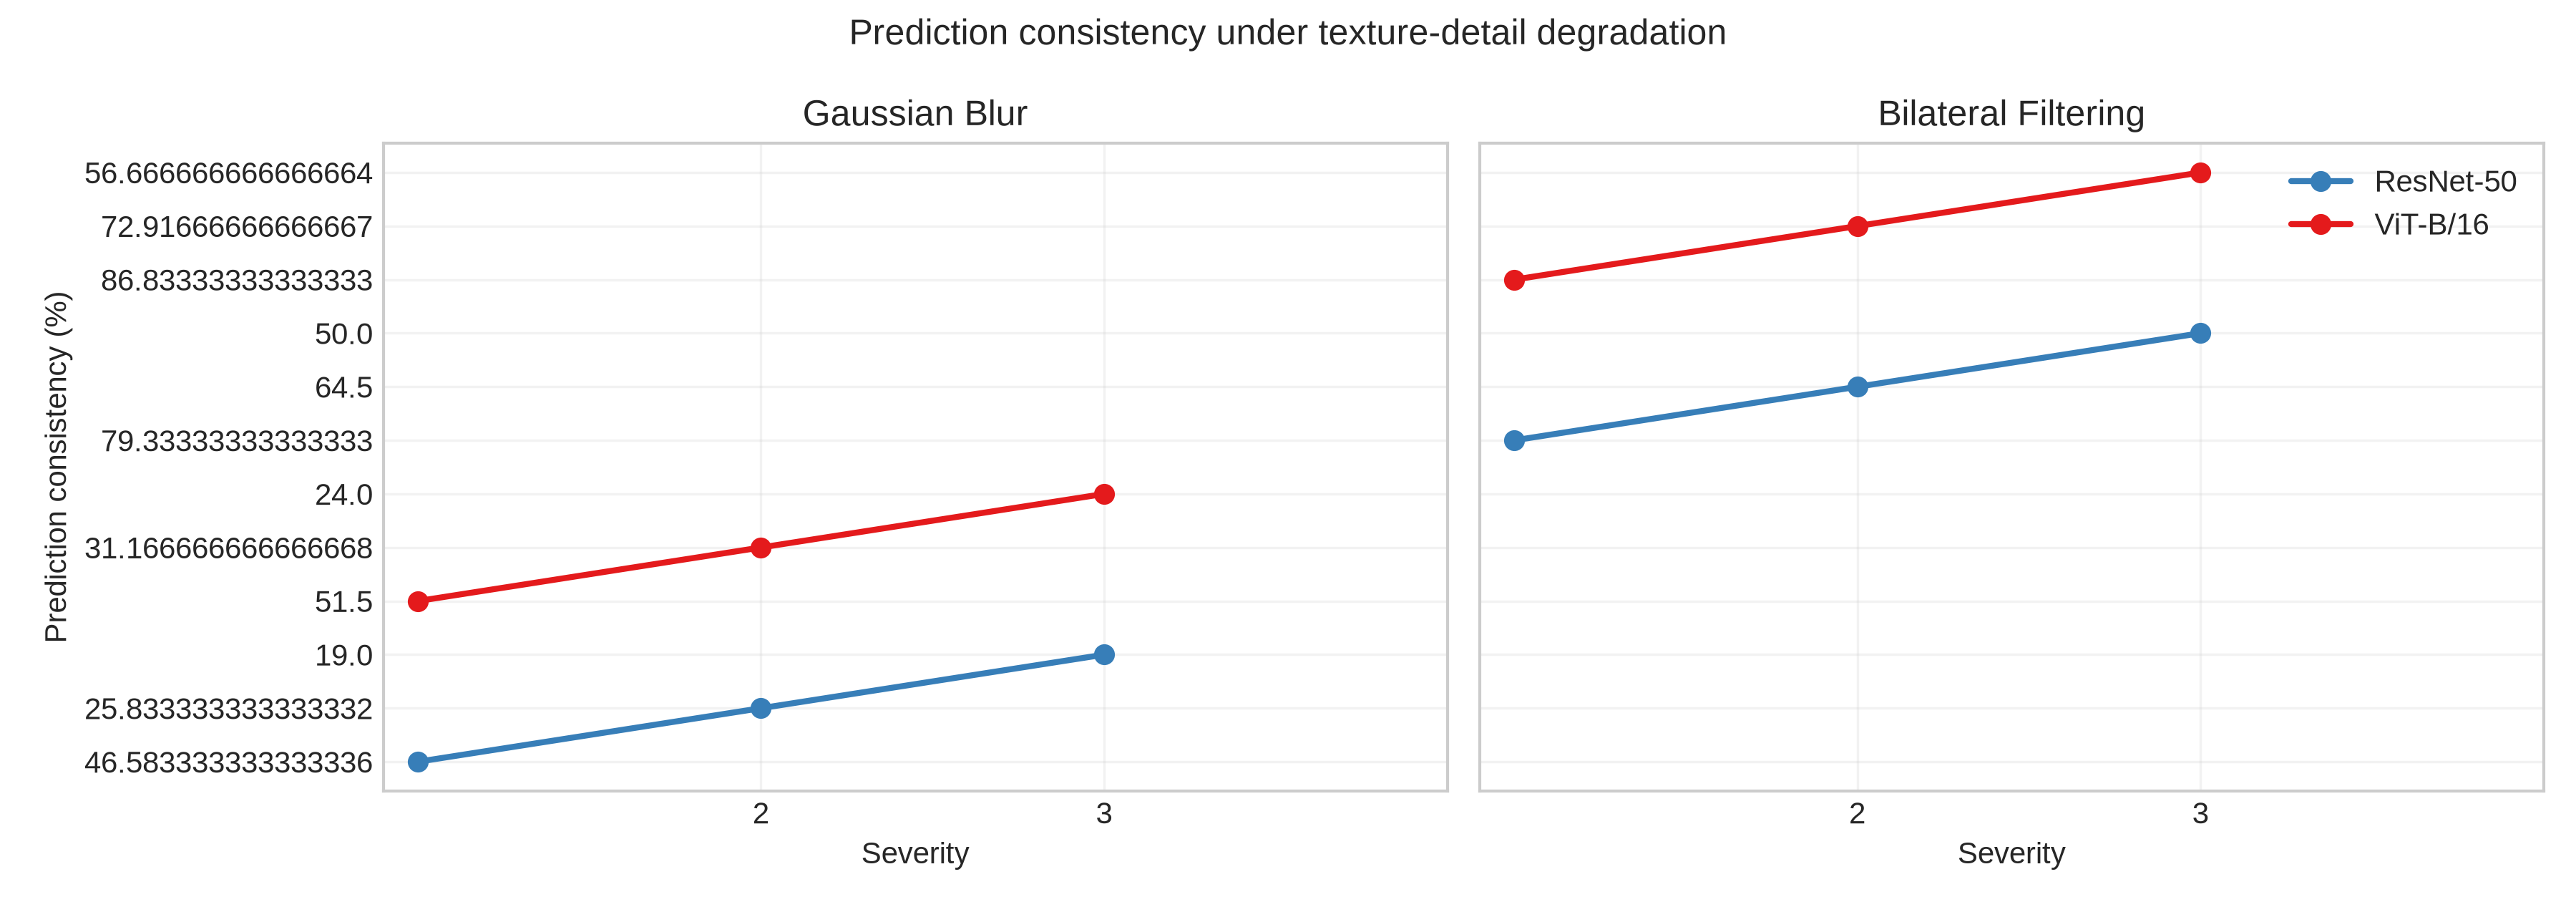

**Figure 3 — Decision distributions.**

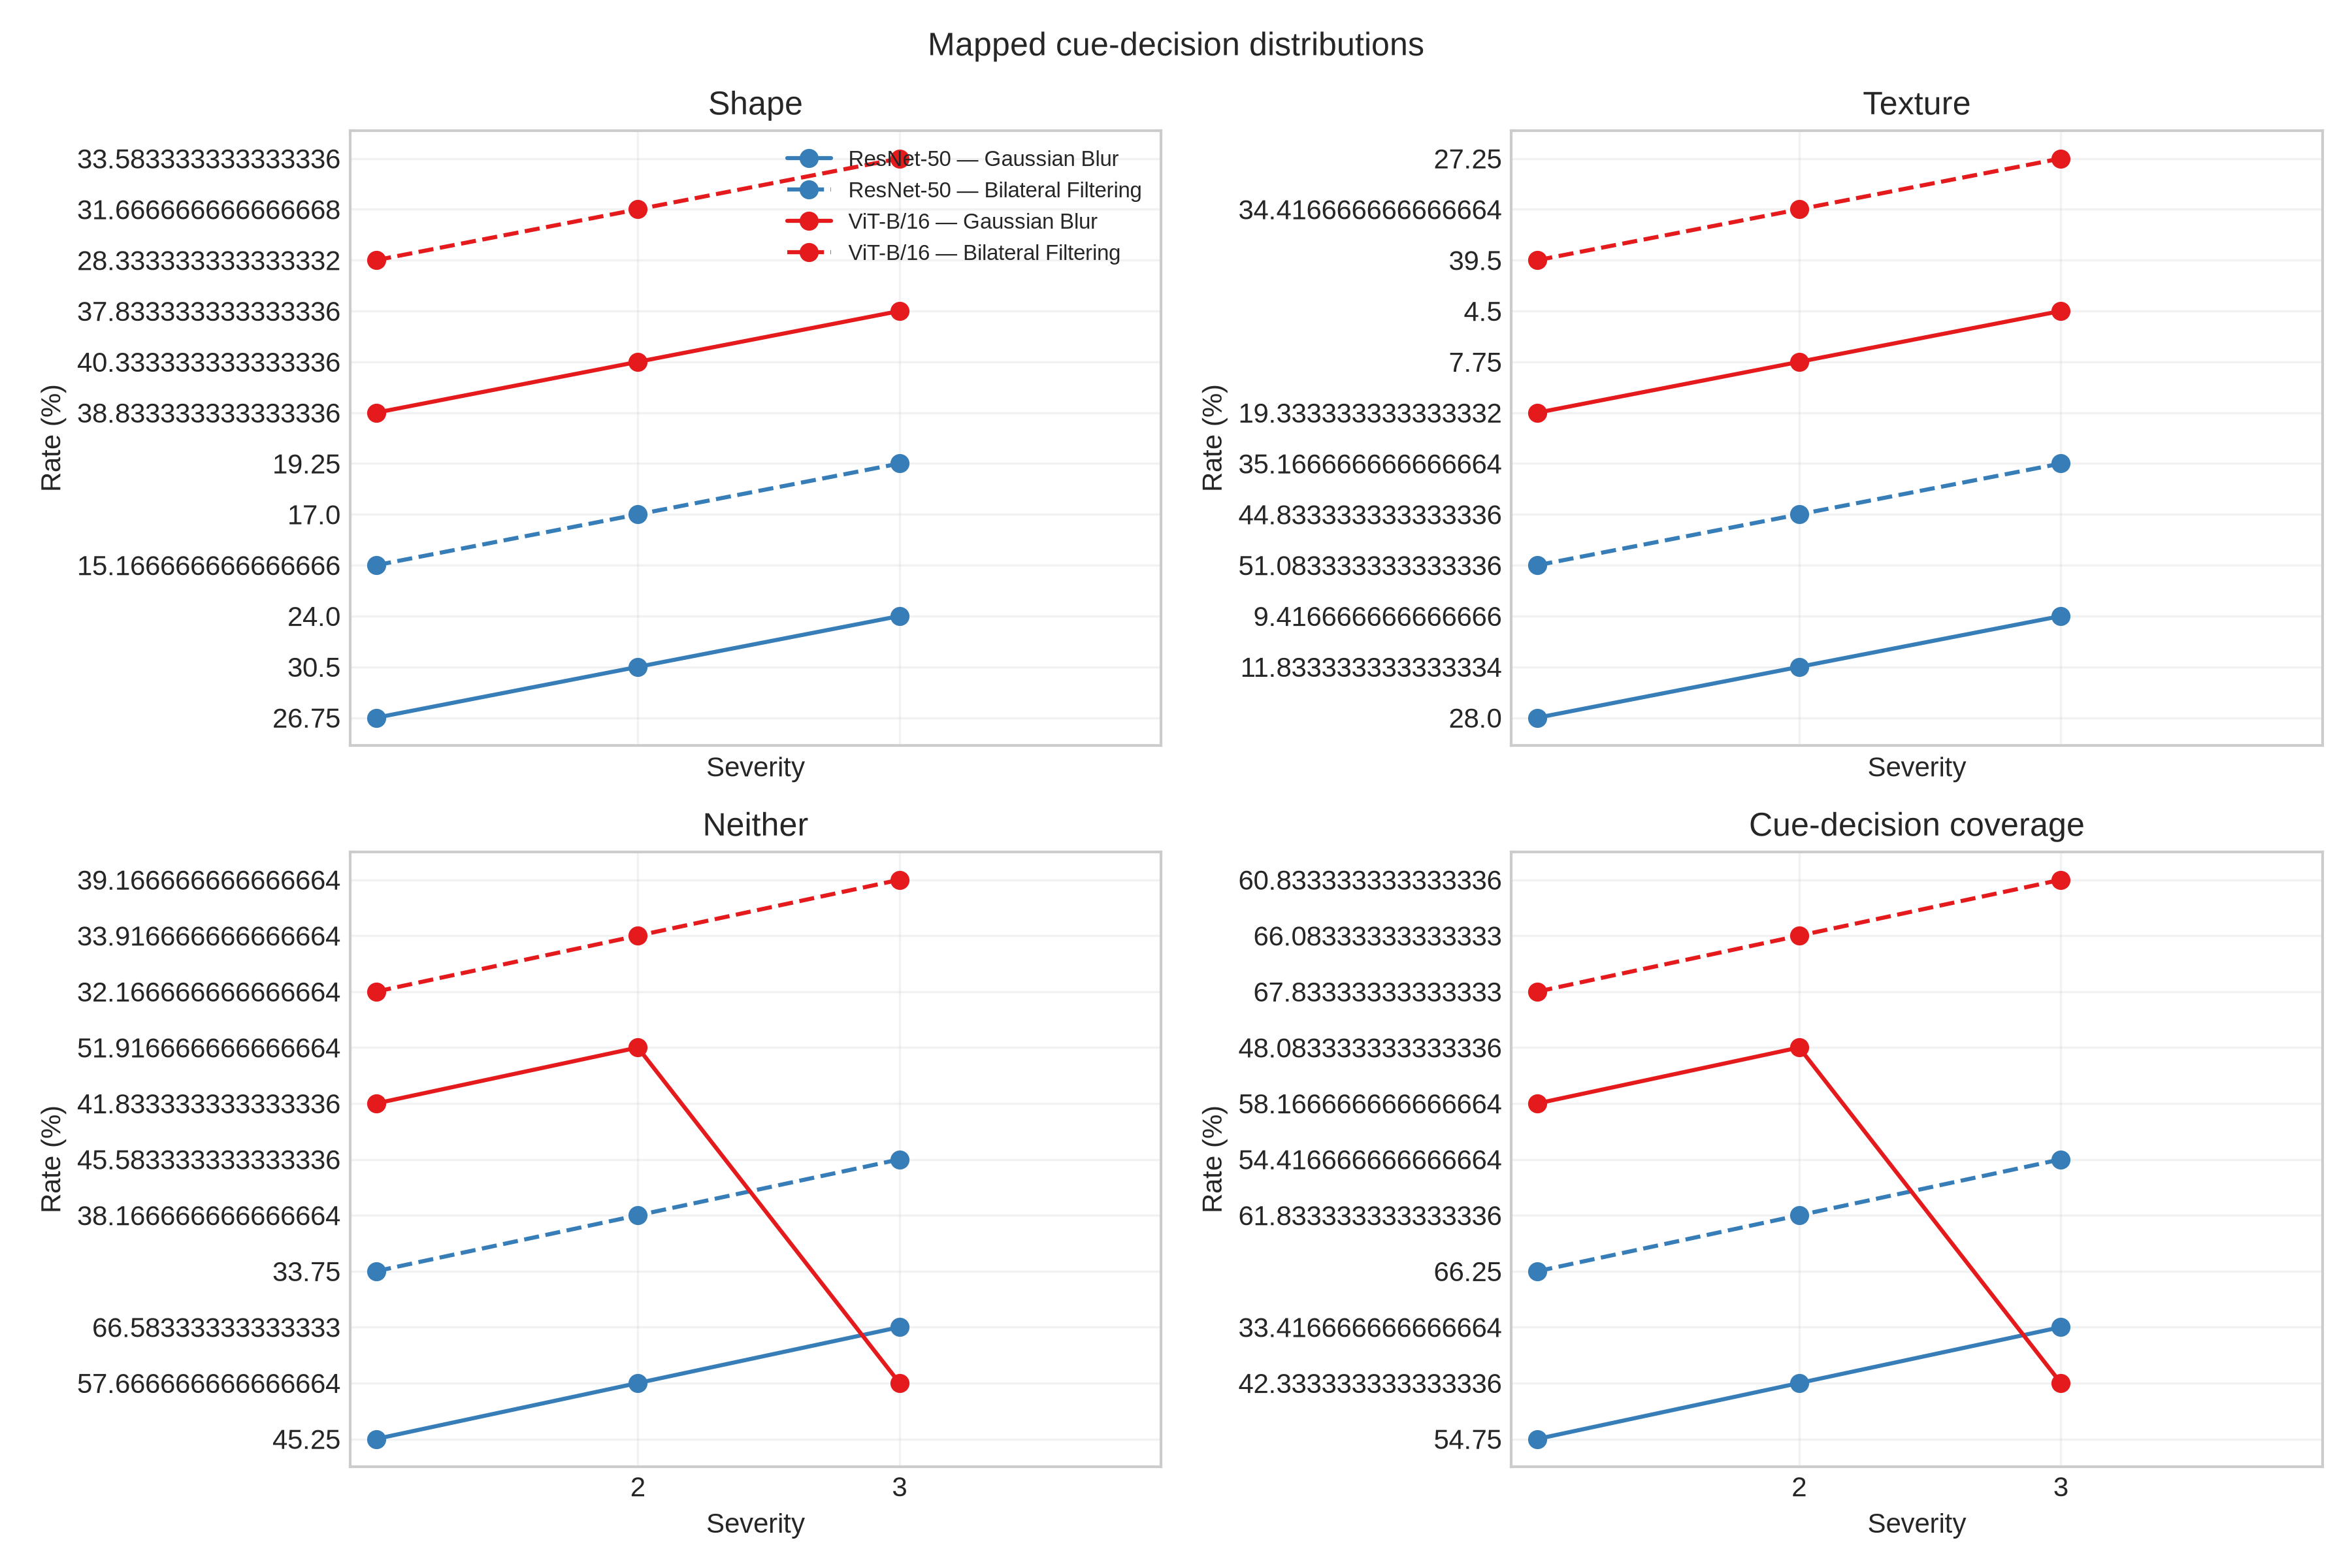

**Figure 4 — Decision retention.**

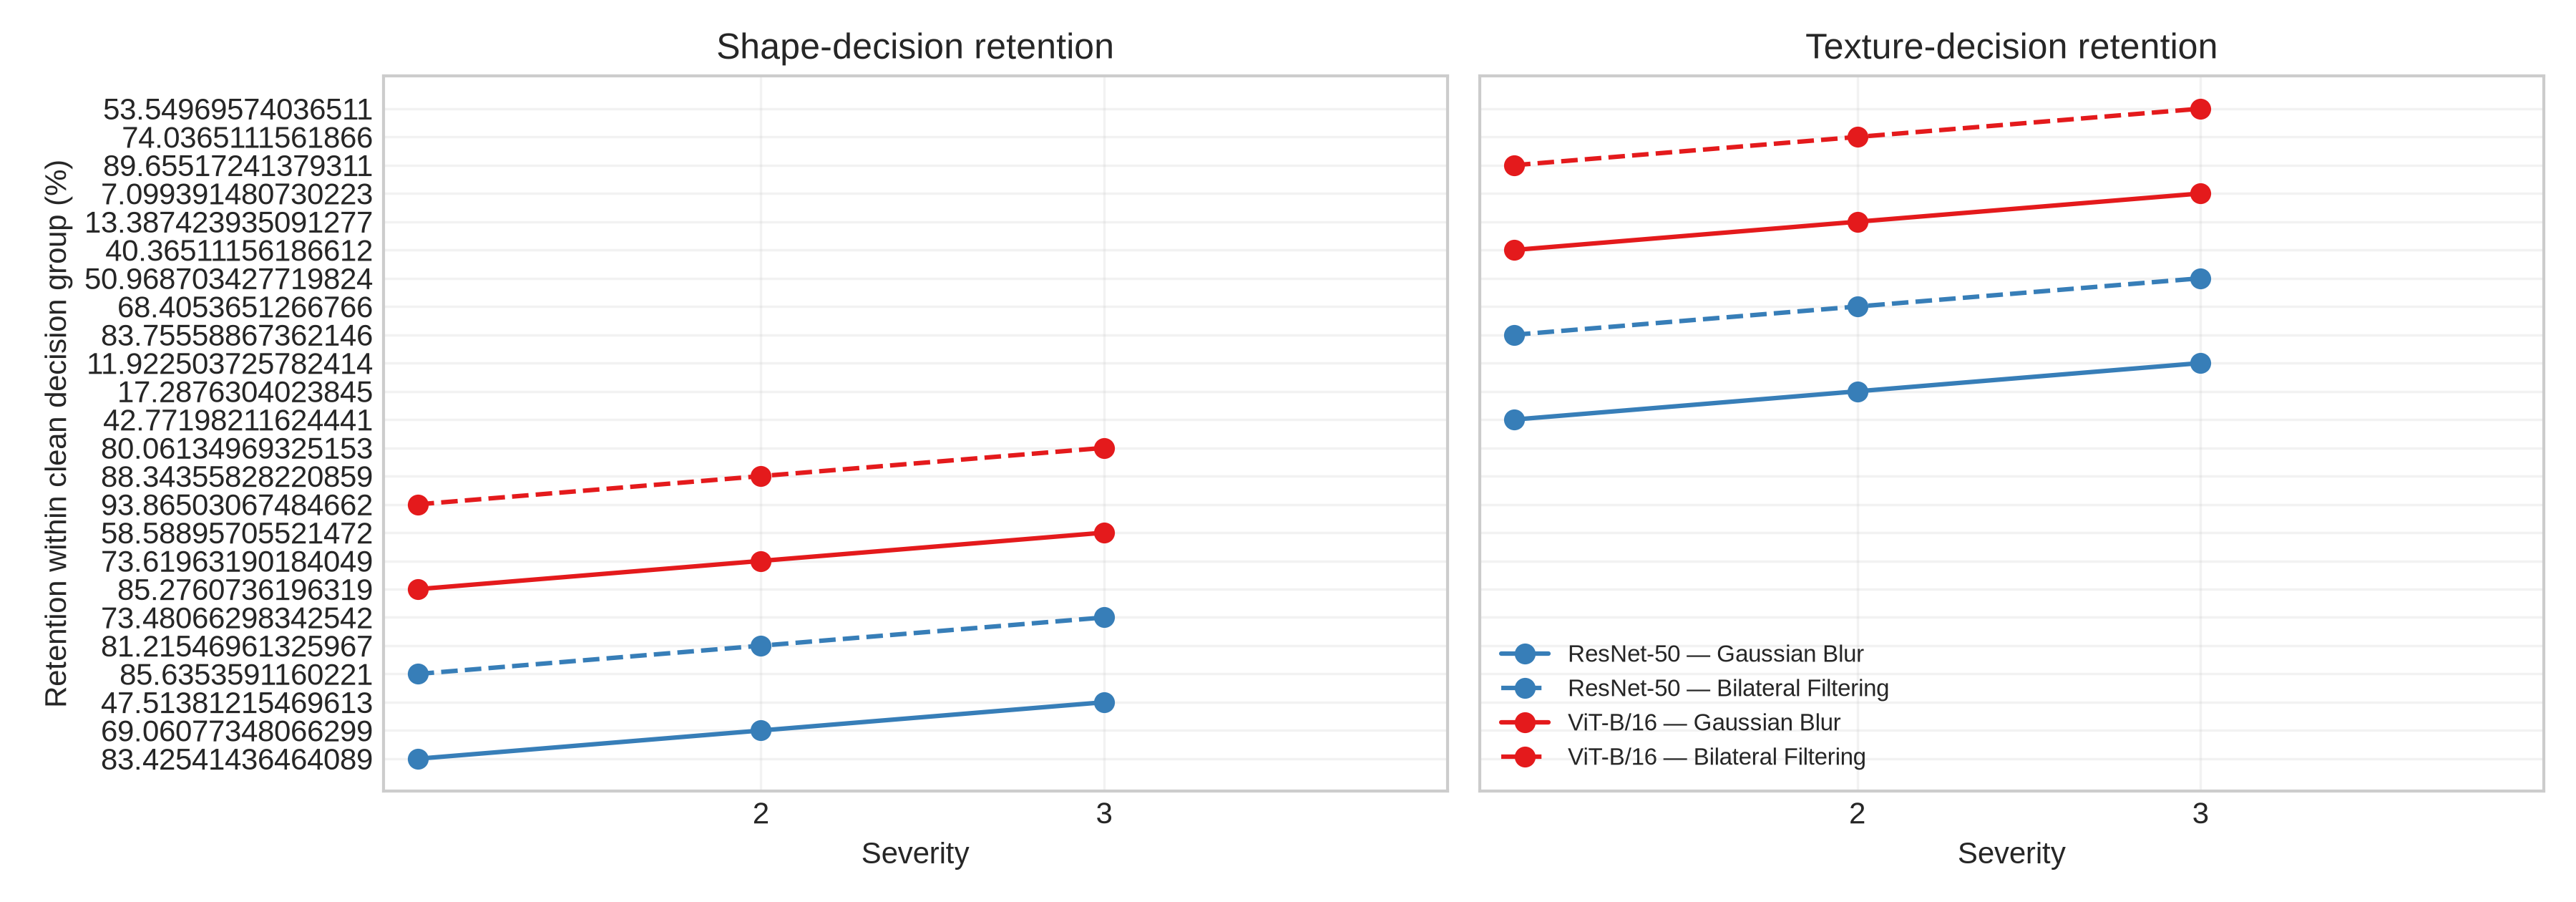

**Figure 5 — Shape Bias and coverage.**

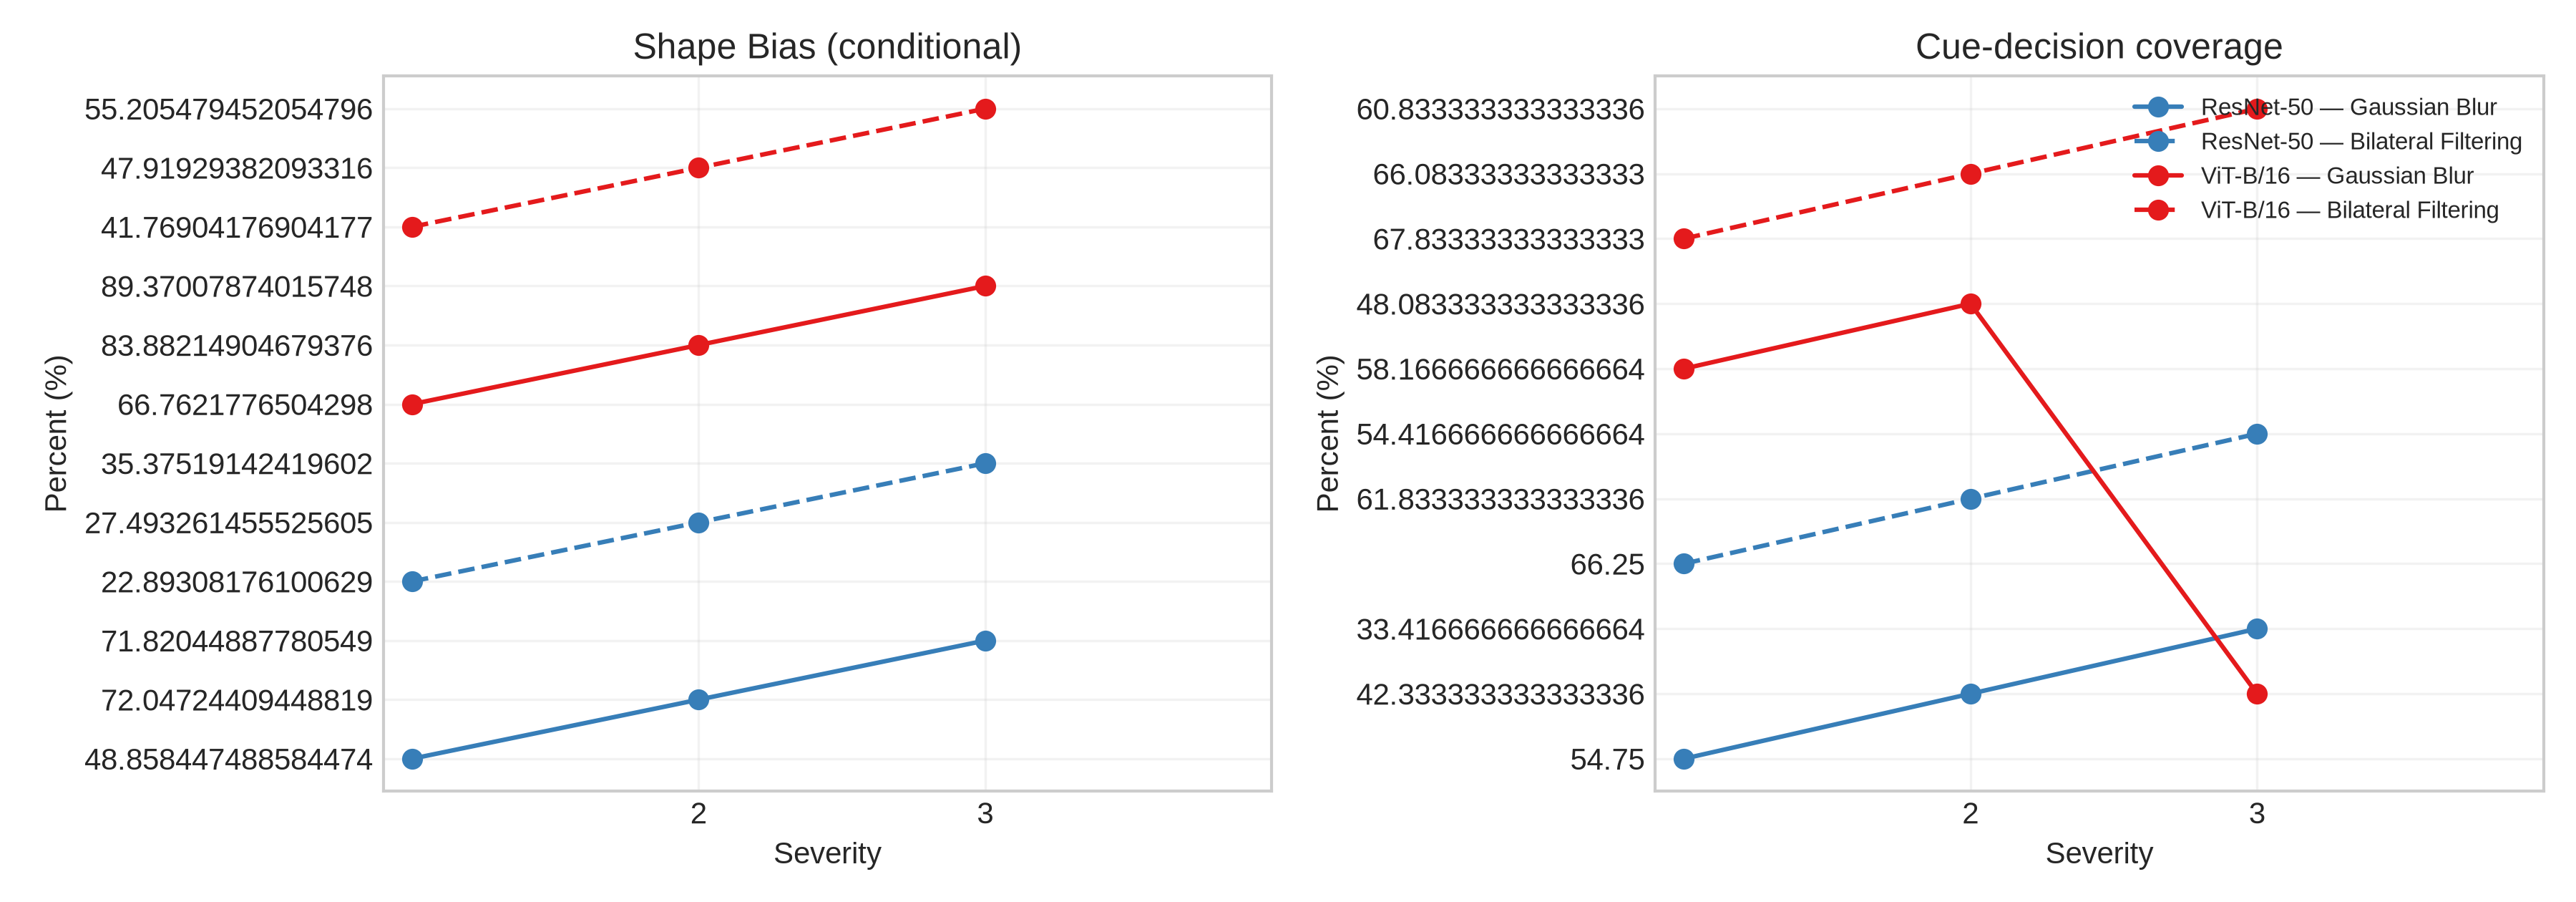

In [7]:
make_figures(summary_rows, FIGURES)
figure_files = [
    ('Figure 2 — Prediction consistency', 'texture_consistency_by_severity.png'),
    ('Figure 3 — Decision distributions', 'texture_decision_distributions.png'),
    ('Figure 4 — Decision retention', 'texture_decision_retention.png'),
    ('Figure 5 — Shape Bias and coverage', 'texture_shape_bias_coverage.png'),
]
for caption, filename in figure_files:
    display(Markdown(f'**{caption}.**'))
    display(DisplayImage(filename=str(FIGURES / filename), width=850))

In [8]:
# Compact, directly data-derived interpretation table for review.
strong = texture_summary[texture_summary.severity == 3].copy()
clean = texture_summary[texture_summary.condition == 'clean'].set_index('model')
strong['consistency_drop_vs_clean_pp'] = strong.apply(lambda r: r.prediction_consistency_percent - clean.loc[r['model'], 'prediction_consistency_percent'], axis=1)
strong['coverage_drop_vs_clean_pp'] = strong.apply(lambda r: r.cue_decision_coverage_percent - clean.loc[r['model'], 'cue_decision_coverage_percent'], axis=1)
display(strong[['model','condition','prediction_consistency_percent','shape_bias_percent','cue_decision_coverage_percent','shape_retention_percent','texture_retention_percent','consistency_drop_vs_clean_pp','coverage_drop_vs_clean_pp']].sort_values(['model','condition']).style.format({c: '{:.2f}' for c in strong.columns if c.endswith('_percent') or c.endswith('_pp')}))

,model,condition,prediction_consistency_percent,shape_bias_percent,cue_decision_coverage_percent,shape_retention_percent,texture_retention_percent,consistency_drop_vs_clean_pp,coverage_drop_vs_clean_pp
6,resnet50,bilateral_s3,50.00,35.38,54.42,73.48,50.97,-50.00,-16.58
3,resnet50,gaussian_s3,19.00,71.82,33.42,47.51,11.92,-81.00,-37.58
13,vit_b_16,bilateral_s3,56.67,55.21,60.83,80.06,53.55,-43.33,-7.42
10,vit_b_16,gaussian_s3,24.00,89.37,42.33,58.59,7.10,-76.00,-25.92


### Reading the figures

Gaussian Blur produces a much sharper fall in consistency and texture-decision retention than Bilateral at the same ordinal severity. A rise in Shape Bias can occur simultaneously with falling coverage and rising Neither, so it must not be read as improved shape classification. The next section checks these aggregate patterns against paired image-level transitions.

## 6. Qualitative failure / transition analysis

Các case bên dưới được **lọc từ paired prediction records** ở Gaussian S3, không chọn thủ công theo hình. Mỗi case hiển thị source và corruption cùng mapped decision của cả hai models.

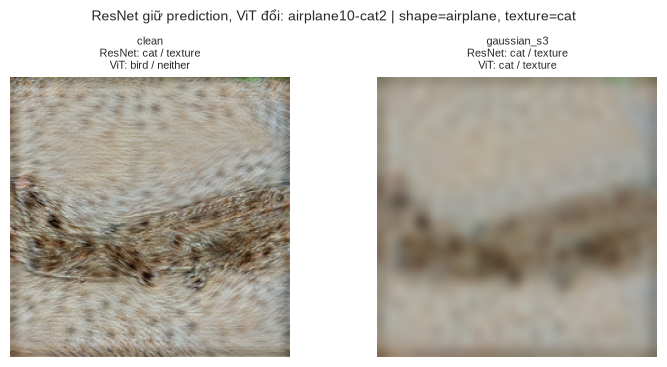

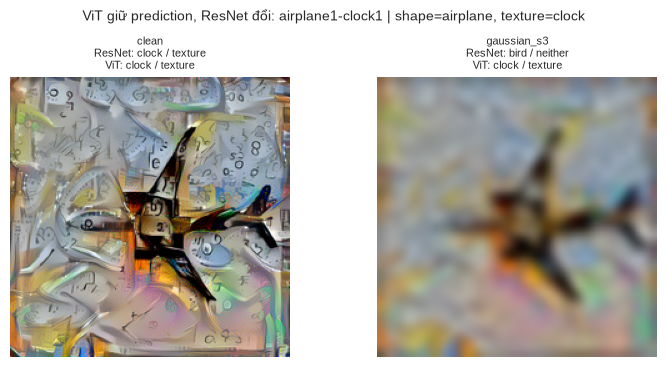

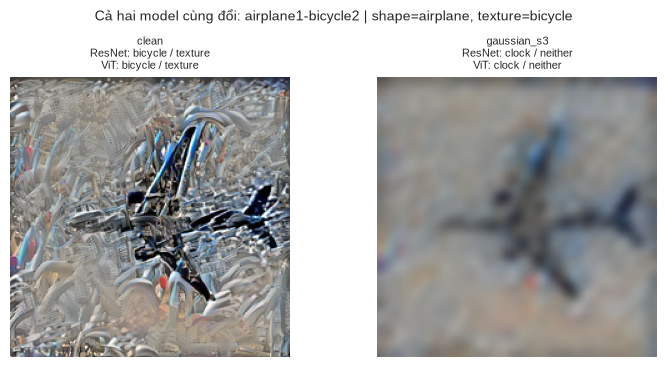

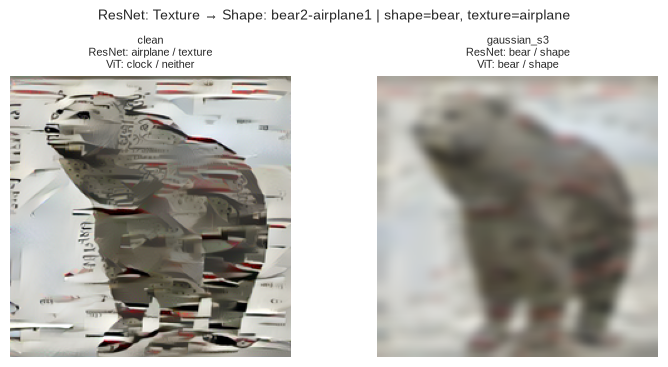

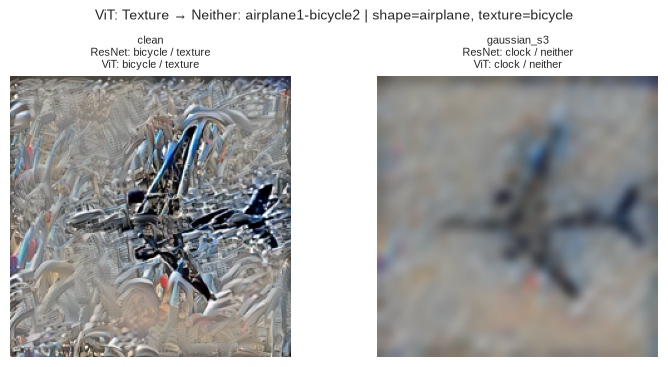

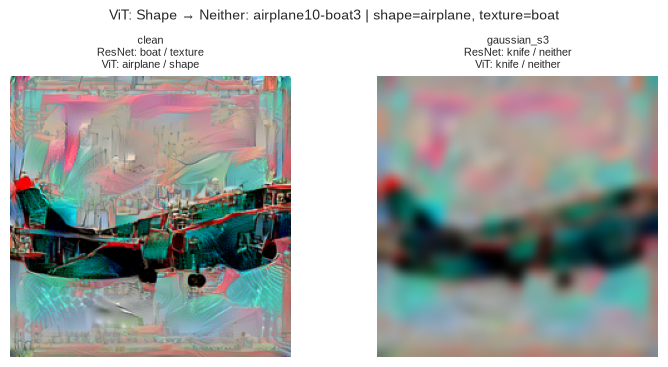

In [9]:
condition_for_cases = 'gaussian_s3'
wide = texture_predictions.pivot(index='image_id', columns=['condition','model'], values=['predicted_category','decision'])
record_by_id = {r['file_id']: r for r in records}

def selected_id(rule):
    matches = [image_id for image_id in wide.index if rule(image_id)]
    if not matches:
        return None
    return sorted(matches)[0]

case_rules = [
    ('ResNet giữ prediction, ViT đổi', lambda i: wide.loc[i, ('predicted_category','clean','resnet50')] == wide.loc[i, ('predicted_category',condition_for_cases,'resnet50')] and wide.loc[i, ('predicted_category','clean','vit_b_16')] != wide.loc[i, ('predicted_category',condition_for_cases,'vit_b_16')]),
    ('ViT giữ prediction, ResNet đổi', lambda i: wide.loc[i, ('predicted_category','clean','vit_b_16')] == wide.loc[i, ('predicted_category',condition_for_cases,'vit_b_16')] and wide.loc[i, ('predicted_category','clean','resnet50')] != wide.loc[i, ('predicted_category',condition_for_cases,'resnet50')]),
    ('Cả hai model cùng đổi', lambda i: wide.loc[i, ('predicted_category','clean','resnet50')] != wide.loc[i, ('predicted_category',condition_for_cases,'resnet50')] and wide.loc[i, ('predicted_category','clean','vit_b_16')] != wide.loc[i, ('predicted_category',condition_for_cases,'vit_b_16')]),
    ('ResNet: Texture → Shape', lambda i: wide.loc[i, ('decision','clean','resnet50')] == 'texture' and wide.loc[i, ('decision',condition_for_cases,'resnet50')] == 'shape'),
    ('ViT: Texture → Neither', lambda i: wide.loc[i, ('decision','clean','vit_b_16')] == 'texture' and wide.loc[i, ('decision',condition_for_cases,'vit_b_16')] == 'neither'),
    ('ViT: Shape → Neither', lambda i: wide.loc[i, ('decision','clean','vit_b_16')] == 'shape' and wide.loc[i, ('decision',condition_for_cases,'vit_b_16')] == 'neither'),
]

for title, rule in case_rules:
    image_id = selected_id(rule)
    assert image_id is not None, f'No actual case for {title}'
    record = record_by_id[image_id]
    fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.7))
    for ax, condition in zip(axes, ['clean', condition_for_cases]):
        ax.imshow(apply_transform(record['image'], condition)); ax.axis('off')
        details=[]
        for model, label in [('resnet50','ResNet'), ('vit_b_16','ViT')]:
            category = wide.loc[image_id, ('predicted_category',condition,model)]
            decision = wide.loc[image_id, ('decision',condition,model)]
            details.append(f'{label}: {category} / {decision}')
        ax.set_title(f'{condition}\n' + '\n'.join(details), fontsize=8)
    fig.suptitle(f'{title}: {image_id} | shape={record["shape_cue"]}, texture={record["texture_cue"]}', fontsize=10)
    fig.tight_layout(); plt.show()

## 7. Discussion

**Observation.** The quantitative tables and paired examples show that both checkpoints change mapped cue decisions as texture detail is degraded. The relative effect is transform-specific: Gaussian causes a more pronounced change than the edge-preserving Bilateral filter at comparable severity levels.

**Interpretation.** A move from Texture to Shape can raise conditional Shape Bias, but a concurrent growth of Neither and lower cue-decision coverage means this is not evidence that the model has become better at recognizing the shape cue. Consistency and decision retention provide the complementary stability evidence.

**Connection to Experiment A.** The clean rows reproduce Shape TV4: ViT-B/16 has higher Shape Bias than ResNet-50. Texture robustness adds a different finding: apparent cue preference and stability under texture degradation are related but not interchangeable. Gaussian S1/S2 predictions are the identical intervention/protocol from Controlled Cue Perturbation and are therefore reused here, not counted as independent evidence.

**Limitations.** Cue-conflict images are stylized rather than a natural-image accuracy benchmark; blur also changes edges/contours; pretrained checkpoints may differ in training recipe; and observed differences cannot be attributed solely to CNN versus Transformer architecture.

In [10]:
def metric(model, condition, column):
    return float(texture_summary[(texture_summary.model == model) & (texture_summary.condition == condition)].iloc[0][column])
for model, label in [('resnet50','ResNet-50'), ('vit_b_16','ViT-B/16')]:
    print(f"{label}: Gaussian S3 consistency={metric(model,'gaussian_s3','prediction_consistency_percent'):.2f}%, Bilateral S3={metric(model,'bilateral_s3','prediction_consistency_percent'):.2f}%; clean Shape Bias={metric(model,'clean','shape_bias_percent'):.2f}%.")

ResNet-50: Gaussian S3 consistency=19.00%, Bilateral S3=50.00%; clean Shape Bias=21.24%.
ViT-B/16: Gaussian S3 consistency=24.00%, Bilateral S3=56.67%; clean Shape Bias=39.80%.


## 8. Conclusion & references

Trên cùng 1.200 cue-conflict images, hai model đều mất stability khi texture detail giảm, đặc biệt dưới Gaussian Blur. Bilateral Filtering ít phá huỷ mapped decisions hơn ở các mức tương ứng, phù hợp với việc nó giữ biên tốt hơn nhưng không chứng minh nó chỉ tác động texture. Kết luận dựa trên prediction consistency, retention, decision distributions, Shape Bias và coverage — không dùng sai Top-1 accuracy trên dữ liệu có hai cue đối nghịch.

**References**

1. Geirhos, R. et al. (2019). *ImageNet-trained CNNs are biased towards texture; increasing shape bias improves accuracy and robustness*. ICLR.
2. Geirhos texture-vs-shape official resources and [`rgeirhos/texture-shape-cue-conflict`](https://huggingface.co/datasets/rgeirhos/texture-shape-cue-conflict).
3. Torchvision pretrained `ResNet50_Weights.IMAGENET1K_V2` and `ViT_B_16_Weights.IMAGENET1K_V1`.